# Modelagem Preditiva com XGBoost (RMSP)

### Objetivo

Treinar modelos **XGBoost** para estimar o risco de **furtos** e **roubos** por célula H3 (resolução 7) e quinzena, e compará-los com o baseline de média histórica da célula.

### Abordagem

É utilizada a mesma base do notebook `modeling_ssp_sp.ipynb`, de forma que o XGBoost possa ser comparado diretamente com o Random Forest.

Decisões adotadas:

- **Mesma base e mesmos folds**: mesmas variáveis de entrada, mesma divisão treino/teste e mesmos folds temporais do notebook original.
- **Com e sem o ano como variável**: assim como no Random Forest, são treinadas duas versões de cada modelo.
- **Avaliação na validação cruzada**: assim como no notebook original, o período de teste (jul/2025 a jun/2026) é separado, mas não é utilizado nesta etapa.

### Execução

O notebook lê o arquivo `datasets/database_processed_h3.csv`, gerado por `processing_coords_ssp_sp.ipynb`. A variável `MODO_RAPIDO` define o escopo da execução:

- **`True`**: apenas o alvo `risco` e 5 combinações de hiperparâmetros;
- **`False`**: os três alvos e 20 combinações de hiperparâmetros.

Como cada alvo é treinado com e sem ano, o tempo de execução é cerca do dobro da versão anterior.

## 1. Bibliotecas e Configuração Inicial

### 1.1 Instalação

Instalação das bibliotecas `xgboost` e `h3`. Caso seja solicitado, o kernel deve ser reiniciado antes de seguir para a próxima célula.

In [1]:
%pip install -q xgboost "h3>=4" scikit-learn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### 1.2 Importação

In [2]:
import os
import time
import numpy as np
import pandas as pd
import h3
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, cross_validate
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### 1.3 Parâmetros de Execução

São definidos a semente aleatória, o caminho da base e o escopo da execução (`MODO_RAPIDO`).

In [3]:
RANDOM_SEED = 42
CAMINHO_DADOS = "datasets/database_processed_h3.csv"

# True: teste rápido (só o alvo "risco" e 5 combinações de hiperparâmetros)
# False: resultados completos (3 alvos e 20 combinações)
MODO_RAPIDO = False

ALVOS = ["risco"] if MODO_RAPIDO else ["risco_furto", "risco_roubo", "risco"]
N_ITER = 5 if MODO_RAPIDO else 20

### 1.4 Espaço de Busca dos Hiperparâmetros

São listados os valores testados na busca aleatória de hiperparâmetros. A cada combinação sorteada, o modelo é treinado e avaliado nos 3 folds temporais.

In [4]:
PARAM_DIST_XGB = {
    "n_estimators":     [200, 400, 800],    # quantas árvores
    "learning_rate":    [0.03, 0.05, 0.1],  # quanto de cada correção é somado
    "max_depth":        [3, 4, 6, 8],       # profundidade máxima de cada árvore
    "min_child_weight": [1, 5, 10],         # evidência mínima para criar uma folha
    "subsample":        [0.7, 0.8, 1.0],    # fração das linhas usada em cada árvore
    "colsample_bytree": [0.6, 0.8, 1.0],    # fração das colunas usada em cada árvore
    "reg_lambda":       [0, 1, 5],          # freio nos valores das folhas
}

## 2. Funções Auxiliares

As funções `metricas`, `get_folds`, `metricas_cv`, `baseline_cv` e `risco_log` são as mesmas do notebook `modeling_ssp_sp.ipynb`.

In [5]:
def metricas(y, pred):
    return {"R2": r2_score(y, pred),
            "MAE": mean_absolute_error(y, pred),
            "RMSE": float(np.sqrt(mean_squared_error(y, pred)))}

In [6]:
def get_folds(df, temps, col_temp, n_folds=3, tam_val=12, gap=0):
    folds = []
    for k in range(n_folds, 0, -1):
        fim_val = len(temps) - tam_val * (k - 1)
        ini_val = fim_val - tam_val
        idx_tr  = np.where(df[col_temp].isin(temps[: ini_val - gap]))[0]
        idx_val = np.where(df[col_temp].isin(temps[ini_val:fim_val]))[0]
        folds.append((idx_tr, idx_val))
    return folds

In [7]:
def metricas_cv(search, train_val, target, features, cv):
    res = cross_validate(
        clone(search.best_estimator_), train_val[features], train_val[target], cv=cv,
        scoring={"R2": "r2", "MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"},
    )
    return pd.DataFrame({"R2": res["test_R2"], "MAE": -res["test_MAE"], "RMSE": -res["test_RMSE"]},
                        index=[f"fold {i}" for i in range(1, len(cv) + 1)])

In [8]:
def baseline_cv(train_val, target, cv):
    linhas = []
    for tr, va in cv:
        media_cel = train_val.iloc[tr].groupby("h3")[target].mean()
        dv = train_val.iloc[va]
        linhas.append(metricas(dv[target], dv["h3"].map(media_cel).fillna(0)))
    return pd.DataFrame(linhas, index=[f"fold {i}" for i in range(1, len(cv) + 1)])

In [9]:
def risco_log(d, col, q=0.99):
    lg = np.log1p(d[col])
    teto = lg.groupby(d["periodo"]).transform(lambda s: s.quantile(q))
    return (lg / teto.replace(0, np.nan)).clip(0, 1).fillna(0)

São adicionadas duas funções:

- **`buscar_xgb`**: busca aleatória de hiperparâmetros do XGBoost, no mesmo formato da função `buscar` do notebook original;
- **`resumo`**: média das métricas nos folds e desvio-padrão do RMSE.

In [10]:
def buscar_xgb(train_val, target, features, cv, n_iter):
    xgb = XGBRegressor(objective="reg:squarederror", tree_method="hist",
                       n_jobs=-1, random_state=RANDOM_SEED)
    search = RandomizedSearchCV(
        xgb, PARAM_DIST_XGB, n_iter=n_iter, cv=cv,
        scoring="neg_root_mean_squared_error",
        random_state=RANDOM_SEED, n_jobs=1, verbose=0,
    )
    search.fit(train_val[features], train_val[target])
    return search

In [11]:
def resumo(tabela):
    return {"R2": tabela["R2"].mean(), "MAE": tabela["MAE"].mean(),
            "RMSE": tabela["RMSE"].mean(), "RMSE_desvio_folds": tabela["RMSE"].std()}

## 3. Leitura e Agregação da Base

### 3.1 Leitura

É lida a base com as ocorrências já associadas às células H3. Apenas as colunas necessárias à modelagem são carregadas.

In [12]:
df_raw = pd.read_csv(CAMINHO_DADOS, usecols=["h3", "DATA", "MES_BO", "ANO_BO", "cnt_crime", "FURTO", "ROUBO"])
print(f"{len(df_raw):,} linhas lidas")

1,789,422 linhas lidas


### 3.2 Agregação por Célula e Quinzena

As ocorrências são agregadas por célula H3 e quinzena, gerando a contagem de furtos (`n_furtos`), de roubos (`n_roubos`) e o total (`n_total`).

In [13]:
df_agg = df_raw.groupby(["h3", "DATA", "MES_BO", "ANO_BO"]).agg(
    n_furtos = ("FURTO", "sum"),
    n_roubos = ("ROUBO", "sum"),
    n_total = ("cnt_crime", "sum")
).reset_index()

## 4. Construção das Variáveis

### 4.1 Chave Temporal

São derivadas as colunas temporais:

- **`QUINZENA`**: 1ª ou 2ª quinzena do mês (equivalente à coluna `DIA_BO` do notebook original);
- **`DATA_AUX`**: data da quinzena (dia 1 ou dia 16), utilizada na construção dos folds;
- **`periodo`**: primeiro dia do mês, utilizado no cálculo do risco e na divisão treino/teste.

In [14]:
parts = df_agg["DATA"].str.split("-", expand=True).astype(int)

df_agg["QUINZENA"] = parts[0]
df_agg["DATA_AUX"] = (pd.to_datetime(dict(year=parts[2], month=parts[1], day=1))
                      + pd.to_timedelta((parts[0] == 2).astype(int) * 15, unit="D"))
df_agg["periodo"] = pd.to_datetime(dict(year=df_agg["ANO_BO"], month=df_agg["MES_BO"], day=1))

### 4.2 Coordenadas das Células

Cada célula H3 é representada pelas coordenadas do seu centro (`lat`, `long`).

In [15]:
centros = {c: h3.cell_to_latlng(c) for c in df_agg["h3"].unique()}
df_agg["lat"] = df_agg["h3"].map(lambda c: centros[c][0])
df_agg["long"] = df_agg["h3"].map(lambda c: centros[c][1])

## 5. Divisão Treino/Teste e Alvo de Risco

São mantidos os mesmos períodos do notebook original:

- **Treino + validação**: jan/2022 a jun/2025;
- **Teste**: jul/2025 a jun/2026.

O conjunto de teste é reservado e não é utilizado nesta etapa, assim como no notebook original. O risco é calculado pela função `risco_log` para furtos, roubos e total.

In [16]:
train_val = df_agg[(df_agg["periodo"] >= "2022-01-01") & (df_agg["periodo"] <= "2025-06-01")].copy().reset_index(drop=True)
test = df_agg[(df_agg["periodo"] >= "2025-07-01") & (df_agg["periodo"] <= "2026-06-01")].copy().reset_index(drop=True)

for d in (train_val, test):
    d["risco_furto"] = risco_log(d, "n_furtos")
    d["risco_roubo"] = risco_log(d, "n_roubos")
    d["risco"] = risco_log(d, "n_total")

print("treino+val:", train_val["periodo"].min().date(), "->", train_val["periodo"].max().date(), f"({len(train_val):,} linhas)")
print("teste     :", test["periodo"].min().date(), "->", test["periodo"].max().date(), f"({len(test):,} linhas)")

treino+val: 2022-01-01 -> 2025-06-01 (51,339 linhas)
teste     : 2025-07-01 -> 2026-06-01 (14,419 linhas)


## 6. Validação Cruzada Temporal

São gerados 3 folds temporais, cada um validando 12 quinzenas (6 meses) posteriores ao período de treino do fold.

In [17]:
temps = np.sort(train_val["DATA_AUX"].unique())
cv = get_folds(train_val, temps, "DATA_AUX", n_folds=3, tam_val=12, gap=0)

for i, (tr, va) in enumerate(cv, 1):
    datas = train_val.iloc[va]["DATA_AUX"]
    print(f"fold {i}: treino até {train_val.iloc[tr]['DATA_AUX'].max().date()} | "
          f"validação {datas.min().date()} -> {datas.max().date()}")

fold 1: treino até 2023-12-16 | validação 2024-01-01 -> 2024-06-16
fold 2: treino até 2024-06-16 | validação 2024-07-01 -> 2024-12-16
fold 3: treino até 2024-12-16 | validação 2025-01-01 -> 2025-06-16


### 7.1 Variáveis de Entrada

São treinadas duas versões, com as mesmas variáveis do notebook original (`modeling_ssp_sp.ipynb`):

- **`com_ano`**: latitude, longitude, mês, quinzena e ano;
- **`sem_ano`**: latitude, longitude, mês e quinzena.

In [18]:
FEATURES = {
    "com_ano": ["lat", "long", "MES_BO", "QUINZENA", "ANO_BO"],
    "sem_ano": ["lat", "long", "MES_BO", "QUINZENA"],
}

### 7.2 Busca de Hiperparâmetros e Avaliação

Para cada alvo, o código:

1. Calcula o baseline `media_celula` na validação cruzada;
2. Para cada versão de variáveis (`com_ano` e `sem_ano`), executa a busca aleatória de hiperparâmetros com os folds temporais;
3. Calcula as métricas de validação cruzada do melhor modelo de cada versão.

In [19]:
resultados_cv, modelos = {}, {}

for alvo in ALVOS:
    inicio = time.time()
    linhas_cv = {"media_celula": resumo(baseline_cv(train_val, alvo, cv))}

    for versao, feats in FEATURES.items():
        busca = buscar_xgb(train_val, alvo, feats, cv, N_ITER)
        modelos[(versao, alvo)] = busca
        linhas_cv[f"xgboost_{versao}"] = resumo(metricas_cv(busca, train_val, alvo, feats, cv))
        print(f"{alvo} | {versao}: melhores hiperparâmetros: {busca.best_params_}")

    resultados_cv[alvo] = pd.DataFrame(linhas_cv).T
    print(f"{alvo}: {time.time() - inicio:.0f} s")

risco_furto | com_ano: melhores hiperparâmetros: {'subsample': 0.8, 'reg_lambda': 5, 'n_estimators': 800, 'min_child_weight': 10, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.8}


risco_furto | sem_ano: melhores hiperparâmetros: {'subsample': 0.8, 'reg_lambda': 5, 'n_estimators': 800, 'min_child_weight': 10, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
risco_furto: 80 s


risco_roubo | com_ano: melhores hiperparâmetros: {'subsample': 0.8, 'reg_lambda': 5, 'n_estimators': 800, 'min_child_weight': 10, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.8}


risco_roubo | sem_ano: melhores hiperparâmetros: {'subsample': 0.8, 'reg_lambda': 5, 'n_estimators': 800, 'min_child_weight': 10, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
risco_roubo: 78 s


risco | com_ano: melhores hiperparâmetros: {'subsample': 0.8, 'reg_lambda': 5, 'n_estimators': 800, 'min_child_weight': 10, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.8}


risco | sem_ano: melhores hiperparâmetros: {'subsample': 1.0, 'reg_lambda': 1, 'n_estimators': 800, 'min_child_weight': 1, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
risco: 81 s


## 8. Resultados

As métricas utilizadas são:

- **R²**: proporção da variação explicada (quanto maior, melhor);
- **MAE**: erro absoluto médio (quanto menor, melhor);
- **RMSE**: raiz do erro quadrático médio (quanto menor, melhor).

Para a comparação com o Random Forest, cada versão deve ser comparada com a versão equivalente do notebook original (`com_ano` com `com_ano` e `sem_ano` com `sem_ano`), que usa a mesma base e os mesmos folds.

In [20]:
for alvo in ALVOS:
    print(f"\n=== {alvo} — validação cruzada (média dos 3 folds) ===")
    display(resultados_cv[alvo].round(4))


=== risco_furto — validação cruzada (média dos 3 folds) ===


,R2,MAE,RMSE,RMSE_desvio_folds
media_celula,0.9262,0.0537,0.0715,0.0004
xgboost_com_ano,0.9229,0.0551,0.0730,0.0010
xgboost_sem_ano,0.9204,0.0564,0.0742,0.0007



=== risco_roubo — validação cruzada (média dos 3 folds) ===


,R2,MAE,RMSE,RMSE_desvio_folds
media_celula,0.8863,0.0789,0.1008,0.0034
xgboost_com_ano,0.8844,0.0798,0.1017,0.0025
xgboost_sem_ano,0.8808,0.0812,0.1033,0.0024



=== risco — validação cruzada (média dos 3 folds) ===


,R2,MAE,RMSE,RMSE_desvio_folds
media_celula,0.9519,0.0416,0.0558,0.0015
xgboost_com_ano,0.9502,0.0430,0.0567,0.0018
xgboost_sem_ano,0.9482,0.0439,0.0579,0.0009


## 8.1 Ensemble de Risco Geral

Assim como no notebook do Random Forest, o risco geral também é estimado combinando as previsões dos modelos de furto e de roubo (versão com ano):

- **Média simples**: média das duas previsões;
- **Máximo**: maior das duas previsões;
- **Regressão linear**: regressão linear com pesos positivos, treinada sobre as previsões de furto e de roubo.

São combinadas as previsões fora da amostra de cada fold, exatamente como no notebook original. Como os pesos da regressão são aprendidos e avaliados nessas mesmas previsões, esse resultado é levemente otimista.

In [21]:
from sklearn.linear_model import LinearRegression

if MODO_RAPIDO:
    print("O ensemble requer MODO_RAPIDO = False (modelos de furto e de roubo).")
else:
    VERSAO_ENS = "com_ano"
    COLS = ["pred_risco_furto", "pred_risco_roubo"]
    feats = FEATURES[VERSAO_ENS]

    partes = []
    for tr, va in cv:
        dv = train_val.iloc[va][["risco"]].copy()
        for alvo in ["risco_furto", "risco_roubo"]:
            est = clone(modelos[(VERSAO_ENS, alvo)].best_estimator_)
            est.fit(train_val.iloc[tr][feats], train_val.iloc[tr][alvo])
            dv["pred_" + alvo] = est.predict(train_val.iloc[va][feats])
        partes.append(dv)
    oof = pd.concat(partes, ignore_index=True)

    reg = LinearRegression(positive=True).fit(oof[COLS], oof["risco"])
    print(f"peso furto: {reg.coef_[0]:.3f} | peso roubo: {reg.coef_[1]:.3f} | intercepto: {reg.intercept_:.3f}")

    def combinar(d, modo):
        f, r = d["pred_risco_furto"], d["pred_risco_roubo"]
        if modo == "media_simples":
            return (f + r) / 2
        if modo == "maximo":
            return np.maximum(f, r)
        return np.clip(reg.predict(d[COLS]), 0, 1)

    MODOS = ["media_simples", "maximo", "regressao_linear"]
    ensemble_cv = pd.DataFrame({m: metricas(oof["risco"], combinar(oof, m)) for m in MODOS}).T

    print("\n=== Ensemble — validação (previsões fora da amostra dos 3 folds) ===")
    print(ensemble_cv.round(4).to_string())

peso furto: 0.641 | peso roubo: 0.325 | intercepto: 0.068

=== Ensemble — validação (previsões fora da amostra dos 3 folds) ===
                      R2     MAE    RMSE
media_simples     0.8990  0.0633  0.0809
maximo            0.9270  0.0526  0.0687
regressao_linear  0.9489  0.0443  0.0575


## 9. Importância das Variáveis

É apresentado o ganho médio de cada variável nas divisões das árvores dos modelos de risco total, com e sem ano.

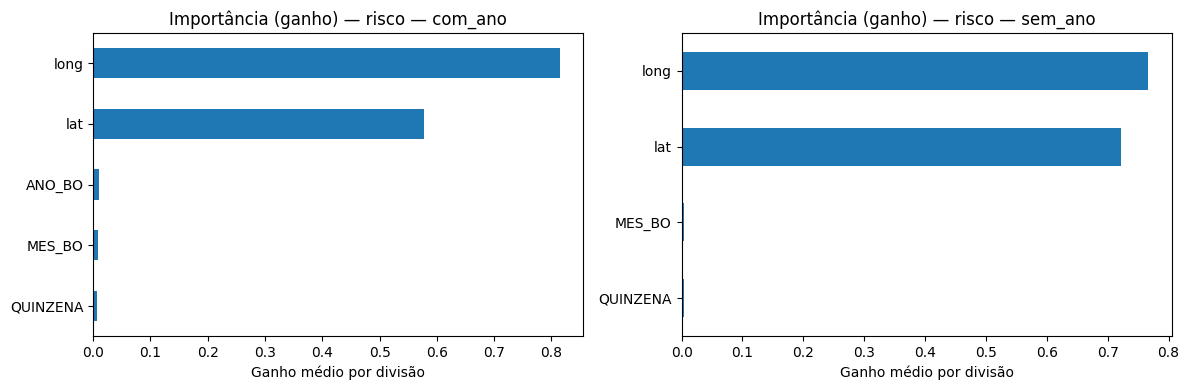

In [22]:
alvo = ALVOS[-1]
fig, axes = plt.subplots(1, len(FEATURES), figsize=(12, 4))
for ax, versao in zip(axes, FEATURES):
    ganho = pd.Series(modelos[(versao, alvo)].best_estimator_.get_booster().get_score(importance_type="gain")).sort_values()
    ganho.plot.barh(ax=ax)
    ax.set_title(f"Importância (ganho) — {alvo} — {versao}")
    ax.set_xlabel("Ganho médio por divisão")
plt.tight_layout()
plt.show()

***Salvar***

In [23]:
os.makedirs("modelos", exist_ok=True)
for (versao, alvo), busca in modelos.items():
    busca.best_estimator_.save_model(f"modelos/xgb_{alvo}_{versao}.json")
print("Modelos salvos na pasta modelos/")

Modelos salvos na pasta modelos/
